In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
import sys
import joblib
import pandas as pd

sys.path.append('../src')

## Чтение данных

In [3]:
data_ft = pd.read_parquet('./data/data_ft.parquet')
data_traces = pd.read_parquet('./data/data_traces.parquet')
data_traces2 = pd.read_parquet('./data/data_traces_short.parquet')
data_ft_full = pd.read_parquet('./data/data_ft_full.parquet')
data_traces_extra = pd.read_parquet('./data/data_X_with_traces.parquet')
data_traces_reflection = pd.read_parquet('data/data_traces_reflection.parquet')
data_rag = pd.read_pickle('./data/data_rag.pkl')

## Создание модели для валидации (используется для примера в будущих тестах)

In [4]:
# contour = 'mlspace'
contour = 'sigma'

In [5]:
RQUID = 'INSERT_YOUR_CLIENT_ID_HERE'
AUTH_DATA = 'INSERT_YOUR_CLIENT_SECRET_HERE'
mlspace_auth = {'OAUTH_URL': 'https://ngw.devices.sberbank.ru:9443/api/v2/oauth',
                'API_URL': 'https://gigachat.devices.sberbank.ru/api/v1',
                'TOKEN': None}
sigma_auth = {'OAUTH_URL': 'https://sm-auth-sd.prom-88-89-apps.ocp-geo.ocp.sigma.sbrf.ru/api/v2/oauth',
              'API_URL': 'https://gigachat.devices.sberbank.ru/api/v1',
              'TOKEN': None}
total_auth = {'mlspace': mlspace_auth,
              'sigma': sigma_auth}

from llm_val.model.MultiThreadGigaModel import MultiThreadGigaModel

In [6]:
model = MultiThreadGigaModel(n_jobs=8,
                             rquid=RQUID,
                             auth_data=AUTH_DATA,
                             oauth_url=total_auth[contour]['OAUTH_URL'],
                             api_url=total_auth[contour]['API_URL'],
                             token=total_auth[contour]['TOKEN'])

In [5]:
from llm_val.utils.api import GigaChatAPI

## Создание Sampler'а и Scorer'а

In [6]:
from llm_val.sampler.TracesSampler import TracesSampler
from llm_val.sampler.TracesSampler2 import TracesSampler2
from llm_val.sampler.RAGSamplerAgent import RAGSamplerAgent
from llm_val.sampler.FastTrackSampler import FastTrackSampler
from llm_val.sampler.ToolTracesSampler import ToolTracesSampler
from llm_val.sampler.TracesSamplerWithReflection import TracesSamplerWithReflection

sampler_ft = FastTrackSampler(data_ft)
sampler_rag = RAGSamplerAgent(data_rag)
sampler_traces = TracesSampler(data_traces)
sampler_traces2 = TracesSampler2(data_ft_full, 
                                 data_traces2)
sampler_traces_tool = ToolTracesSampler(data_traces_extra)
sampler_traces_reflection = TracesSamplerWithReflection(data_traces_reflection)

In [7]:
from llm_val.scorer.UniversalScorer import UniversalScorer
from llm_val.utils.metrics import METRICS

scorer = UniversalScorer(metrics=METRICS)

## Этап 2

### Тест 4.3.1 – Валидация тестового датасета

#### Ожидаемые колонки от субтестов

Агрегирующий тест извлекает данные из отчетов субтестов, читая первую строку первого датафрейма из списка `result_dataframes`. 

Субтесты должны возвращать отчеты со следующими колонками:

| Колонка | Тип | Описание |
| :--- | :--- | :--- |
| **Проверка** | `str` | Название конкретной проверки (субтеста). Если колонка отсутствует, используется имя модуля (`default_name`). |
| **Результат** | `str` | Краткий итог проверки в виде "Пройдена" / "Не пройдена". Если колонка отсутствует, подставляется значение по умолчанию `-`. |
| **Комментарий** | `str` | Текстовое пояснение к результату. Если колонка отсутствует, подставляется пустая строка `""`. |

In [14]:
from llm_val.val_test.middlegame.valtest_test_dataset_val import valtest_test_dataset_val

res431 = valtest_test_dataset_val(sampler_ft, 
                                  subtests=['valtest_exact_duplicates',
                                            'valtest_outliers_by_char_count',
                                            'valtest_dataset_size_compliance'])
res431['report']['result_dataframes'][0].style.set_properties(**{'white-space': 'pre-wrap', 'max-width': '200px'})

,Проверка,Результат,Комментарий
0,Отсутствие полных дубликатов среди примеров [вспомогательная проверка],Не пройдена,"Номера строк с примерами-дубликатами: (10, 17)"
1,Отсутствие выбросов среди примеров по количеству символов [вспомогательная проверка],Не пройдена,"Номера строк с примерами, являющимися выбросами: [6, 11, 19]"
2,Соответствие размера датасетов согласованному количеству примеров [основная проверка],Не пройдена,"После исключения дубликатов и выбросов остаётся 15 примеров, что меньше требуемого минимума 250. Необходимо добавить не менее 235 примеров или обосновать сохранение части исключённых записей."


In [26]:
import typing as tp
from llm_val.sampler.Sampler import Sampler

class IntersSampler(Sampler):
    
    def __init__(self, 
                 test: pd.DataFrame,
                 train: pd.DataFrame):
        test = self._preproc(test)
        train = self._preproc(train)
        super().__init__(test=test, train=train)


    def _preproc(self, var: pd.DataFrame) -> tp.Dict[str, pd.DataFrame]:
        X = pd.DataFrame()
        y = pd.DataFrame()
        X['input_query'] = var['input_query']
        X['output_answer'] = var['output_answer']
        X['session_id'] = range(len(X))
        return {'X': X, 'y': y}
    
sampler_inters = IntersSampler(test=data_ft[:19], train=data_ft[9:])

#### Тест 4.3.1.1 - Соответствие датасетов верифицированному формату

Обратите внимание на параметр `optional_columns` в этой подпроверке. В ней можно указать все колонки, которые **не** нужно проверять в этом тесте.

На текущий момент в тесте по умолчанию требуются колонки (формат определяется по наличию/отсутствию колонки `'dialogue'` в датасете):

Для QA-формата: `['solution_version', 'scenario', 'session_id', 'query_id', 'input_query_count', 'input_query', 'output_answer', 'reference_answer', 'assessor_id']`.

Для диалогового формата: `['solution_version', 'scenario', 'session_id', 'assessor_id', 'dialogue']`.

In [10]:
from llm_val.val_test.middlegame.subtests_test_dataset_val.valtest_format_check import valtest_format_check

res_4311 = valtest_format_check(sampler=sampler_traces2)

In [11]:
res_4311['report']['result_dataframes'][0].style.set_properties(**{'white-space': 'pre-wrap', 'max-width': '200px'})

,Проверка,Наличие нарушений формата,Результат,Комментарий
0,"Отсутствие пропусков в датасете, несоответствий типа колонок и их полного отсутствия [основная проверка]","{'NA': {}, 'type': {}, 'col': ['solution_version', 'scenario', 'input_query_count', 'reference_answer']}",Не пройдена,"Наименования отсутствующих необходимых колонок: ['solution_version', 'scenario', 'input_query_count', 'reference_answer']"


#### Тест 4.3.1.2 – Отсутствие полных дубликатов среди примеров

In [20]:
from llm_val.val_test.middlegame.subtests_test_dataset_val.valtest_exact_duplicates import valtest_exact_duplicates

res4312 = valtest_exact_duplicates(sampler_inters)
res4312['report']['result_dataframes'][0].style.set_properties(**{'white-space': 'pre-wrap', 'max-width': '200px'})

,Проверка,Доля дубликатов,Результат,Комментарий
0,Отсутствие полных дубликатов среди примеров [вспомогательная проверка],0.105263,Не пройдена,"Номера строк с примерами-дубликатами: (10, 17)"


#### Тест 4.3.1.3 – Отсутствие семантических дубликатов среди примеров

Для нахождения дубликатов в аргумент `embedding_client` подаётся **OpenAI-совместимый клиент** с методом `embeddings.create(model=..., input=[...])`; название эмбеддинг-модели передаётся отдельно через `embedding_model_name`. Ниже показано, как поднять такой клиент функцией `configure_client` для GigaChat через прокси `gpt2giga`.

In [75]:
import os
import sys
import time
import socket
import threading
import subprocess
from openai import OpenAI

giga = GigaChatAPI(contour=contour, api_url=total_auth[contour]['API_URL'], auth_data=AUTH_DATA)
base_url = total_auth[contour]['API_URL']

def ensure_proxy_killed(port=8090):
    """Force-kill any process listening on the given port (mandatory)."""
    try:
        result = subprocess.run(
            f"netstat -ano | findstr :{port}",
            shell=True, capture_output=True, text=True
        )
        for line in result.stdout.splitlines():
            if "LISTENING" in line:
                pid = line.strip().split()[-1]
                subprocess.run(f"taskkill /F /PID {pid}", shell=True)
    except Exception:
        pass

ensure_proxy_killed(8090)

def start_proxy_subprocess(base_url, access_token, host='127.0.0.1', port=8090):
    env = os.environ.copy()
    env.update({
        'GPT2GIGA_MODE': 'DEV',
        'GPT2GIGA_HOST': host,
        'GPT2GIGA_PORT': str(port),
        'GPT2GIGA_LOG_FILENAME': 'proxy.log',
        'GPT2GIGA_ENABLE_API_KEY_AUTH': 'False',
        'GIGACHAT_ACCESS_TOKEN': access_token,
        'GIGACHAT_BASE_URL': base_url,
        'GIGACHAT_VERIFY_SSL_CERTS': 'False',
    })
    process = subprocess.Popen([sys.executable, '-m', 'gpt2giga.api_server'],
                               env=env,
                               stdout=subprocess.DEVNULL,
                               stderr=subprocess.DEVNULL)
    return process

def wait_port(host, port, timeout=40):
    """Ждёт, пока порт станет доступным."""
    deadline = time.time() + timeout
    while time.time() < deadline:
        try:
            with socket.create_connection((host, port), timeout=1):
                return True
        except OSError:
            time.sleep(0.5)
    return False

def configure_client_subprocess(base_url, access_token, host='127.0.0.1', port=8090, timeout=500):
    """
    Запускает прокси через subprocess, ждёт его готовности и возвращает OpenAI-клиент,
    а также объект процесса (чтобы потом завершить).
    """
    process = start_proxy_subprocess(base_url, access_token, host, port)
    if not wait_port(host, port):
        raise RuntimeError(f"Прокси не запустился на {host}:{port} за отведённое время")
    client = OpenAI(base_url=f'http://{host}:{port}/v1', api_key='123', timeout=timeout)
    return client, process

embedding_client, proxy_process = configure_client_subprocess(
    base_url=base_url,
    access_token=giga.token
)

In [76]:
exact_duplicates = valtest_exact_duplicates(sampler_traces2)['precomputed']['duplicates']

In [77]:
from llm_val.val_test.middlegame.subtests_test_dataset_val.valtest_semantic_duplicates import valtest_semantic_duplicates

res_4313 = valtest_semantic_duplicates(sampler=sampler_traces2,
                                       exact_duplicates=exact_duplicates,
                                       embedding_client=embedding_client,
                                       threshold_duplicates = 0.95)

In [78]:
res_4313['report']['result_dataframes'][0].style.set_properties(**{'white-space': 'pre-wrap', 'max-width': '200px'})

,Проверка,Доля семантических дубликатов,Результат,Комментарий
0,Отсутствие семантических дубликатов среди примеров [вспомогательная проверка],0.107143,Не пройдена,"Пары дубликатов: (28, 46), (113, 167), (56, 69), (125, 145), (115, 148), (91, 226), (22, 136), (57, 103), (95, 103), (84, 239), (2, 209), (2, 144), (138, 195), (150, 221), (42, 136), (57, 95), (147, 230)"


#### Тест 4.3.1.4 – Отсутствие пересечений примеров тестового датасета с примерами валидационного датасета


In [23]:
from llm_val.val_test.middlegame.subtests_test_dataset_val.valtest_train_test_intersections import valtest_train_test_intersections

res4314 = valtest_train_test_intersections(sampler_inters)
res4314['report']['result_dataframes'][0].style.set_properties(**{'white-space': 'pre-wrap', 'max-width': '200px'})

,Проверка,Доля пересечений,Результат,Комментарий
0,Отсутствие пересечений примеров тестового датасета с примерами валидационного датасета [вспомогательная проверка],0.526316,Не пройдена,"Номера строк с пересекающимися примерами (из тестовой выборки): 9, 10, 11, 12, 13, 14, 15, 16, 17, 18. Рекомендуется удалить дубликаты из валидационного датасета."


#### Тест 4.3.1.5 – Отсутствие выбросов среди примеров по количеству символов

In [31]:
from llm_val.val_test.middlegame.subtests_test_dataset_val.valtest_outliers_by_char_count import valtest_outliers_by_char_count

res4315 = valtest_outliers_by_char_count(sampler_ft)
res4315['report']['result_dataframes'][0].style.set_properties(**{'white-space': 'pre-wrap', 'max-width': '200px'})

,Проверка,Доля выбросов,Результат,Комментарий
0,Отсутствие выбросов среди примеров по количеству символов [вспомогательная проверка],0.150000,Не пройдена,"Номера строк с примерами, являющимися выбросами: [6, 11, 19]"


#### Тест 4.3.1.6 – Наличие в датасете всех ожидаемых категорий вопросов / сценариев в согласованных пропорциях

In [32]:
# глупо добавляем темы в данные
categories = ["Портфель и инвестиции","Портфель и инвестиции","Портфель и инвестиции","Вклады и сбережения","Портфель и инвестиции","Вклады и сбережения",
            "Вклады и сбережения","Вклады и сбережения","Портфель и инвестиции","Вклады и сбережения","Общие финансы и соцподдержка","Портфель и инвестиции",
            "Портфель и инвестиции","Общие финансы и соцподдержка","Общие финансы и соцподдержка","Общие финансы и соцподдержка","Общие финансы и соцподдержка",
            "Общие финансы и соцподдержка","Портфель и инвестиции","Портфель и инвестиции"
            ]
# Проверяемое распределение
expected_distribution = {"Портфель и инвестиции": 0.45,
                         "Вклады и сбережения": 0.25,
                         "Общие финансы и соцподдержка": 0.30} 

In [33]:
data_ft_4316 = data_ft.copy()
data_ft_4316['scenario'] = categories
sampler_ft4316 = FastTrackSampler(data_ft_4316)

In [35]:
from llm_val.val_test.middlegame.subtests_test_dataset_val.valtest_dataset_category_proportions import valtest_dataset_category_proportions

res4316 = valtest_dataset_category_proportions(sampler_ft4316, 
                                               expected_distribution)
res4316['report']['result_dataframes'][0].style.set_properties(**{'white-space': 'pre-wrap', 'max-width': '400px'})

,Проверка,Результат,Метрика,Комментарий
0,Проверка соответствия фактического распределения категорий в датасете априорному распределению из отчёта о разработке [основная проверка],Пройдена,0.000000,PSI = 0.0000 (порог: 0.1) Макс. отклонение доли = 0.0000


#### Тест 4.3.1.7 – Соответствие размера датасетов согласованному количеству примеров

In [12]:
from llm_val.val_test.middlegame.subtests_test_dataset_val.valtest_dataset_size_compliance import valtest_dataset_size_compliance

res4317 = valtest_dataset_size_compliance(sampler_ft)
res4317['report']['result_dataframes'][0].style.set_properties(**{'white-space': 'pre-wrap', 'max-width': '400px'})

,Проверка,Результат,Комментарий
0,Соответствие размера датасетов согласованному количеству примеров [основная проверка],Не пройдена,"После исключения дубликатов и выбросов остаётся 20 примеров, что меньше требуемого минимума 250. Необходимо добавить не менее 230 примеров или обосновать сохранение части исключённых записей."


### Тест 4.3.4 - Проверка связности трейсов

In [13]:
from llm_val.val_test.traces.valtest_trace_connectivity import valtest_trace_connectivity
res434 = valtest_trace_connectivity(sampler_traces)

In [17]:
display(res434['report']['result_dataframes'][0])

,Проверка,Результат проверки,Светофор
0,Количество стартовых нод,4,yellow
1,Количество выходных нод,2,yellow
2,Количество компонент связности,1,green


### Тест 4.3.5 - Анализ использования нод и инструментов условного графа

In [37]:
from llm_val.val_test.traces.valtest_nodes_usage_analysis import valtest_nodes_usage_analysis
res435 = valtest_nodes_usage_analysis(sampler_traces)

In [38]:
display(res435['report']['result_dataframes'][0])

,Результат теста,Светофор
0,Все ноды и инструменты представлены достаточно...,green


## Этап 3

### Тест 5.3.1 - Оценка достаточности перекрытия при экспертной оценке


Обратите внимание на параметр `is_justified`: если вы ставите его `True`, то тест не выдаст красный светофор.

Для настройки порога можно использовать:
- `green_semaphore_threshold` — минимально необходимое число асессоров для зелёного светофора (имеет наивысший приоритет)
- `n_categories` — число возможных вариантов оценки. Порог вычисляется как N+1. Используйте, если в данных отсутствуют примеры каких-то из вариантов и автоматический расчёт через `nunique()` занижает порог
- Если ничего не задано — порог определяется автоматически как количество уникальных значений метрики в данных + 1

In [5]:
from llm_val.val_test.data_quality.valtest_markup_overlap_sufficiency import valtest_markup_overlap_sufficiency

res_531 = valtest_markup_overlap_sufficiency(sampler_ft,
                                             data_type='test')

In [6]:
print(f'Перекрытие: {res_531["precomputed"]["overlap_statistics"]}')

Перекрытие: {'final_metric': 2}


In [7]:
display(res_531['report']['result_dataframes'][0])

,Название метрики,Минимальное перекрытие,Светофор
0,final_metric,2,red


### Тест 5.3.2 - Оценка согласованности асессоров


In [ ]:
from llm_val.val_test.data_quality.valtest_annotation_quality_agent import valtest_annotation_quality_agent

res_532 = valtest_annotation_quality_agent(sampler_ft,
                                           data_type='test')

In [9]:
print(f'Статистики: {res_532["precomputed"]}')

Статистики: {'spearman_stat': nan, 'krippendorf_stat': nan, 'cohen_stat': 0.027777777777777773, 'fleiss_stat': nan}


In [10]:
display(res_532['report']['result_dataframes'][0])

,Название статистики,Значение статистики,Светофор
0,Попарная корреляция Спирмена,None,gray
1,Альфа Криппендорфа,None,gray
2,Каппа Коэна,0.027778,red
3,Каппа Флейсса,None,gray


### Тест 5.3.3 - Достижение требуемого качества по ключевой метрике

In [11]:
from llm_val.val_test.model_quality.valtest_metric_agent import valtest_metric_agent

res_533 = valtest_metric_agent(sampler_ft,
                               scorer=scorer,
                               main_metric='single_mean_final_metric',
                               data_type='test')

In [12]:
print(f'Значения метрик: {res_533["precomputed"]["metric_value"]}')

Значения метрик: {'single_mean_final_metric': 0.8}


In [13]:
display(res_533['report']['result_dataframes'][0])

,"Значение ключевой метрики ""single_mean_final_metric"" на test",Результат теста
0,0.8,green


### Тест 5.3.4 - Статистическая значимость преодоления бизнес-порога

In [52]:
from llm_val.val_test.model_quality.valtest_stat_significance import valtest_stat_significance

res_534 = valtest_stat_significance(sampler=sampler_ft,
                                    scorer=scorer,
                                    metric_agg='single_mean',
                                    data_type='test',
                                    main_column='final_metric',
                                    value_threshold=0.5,
                                    extra_samplers=None,
                                    is_info=False,
                                    p_value=None)

In [53]:
display(res_534['report']['result_dataframes'][0])

,Значение p-value на test,Результат теста
0,0.002018,green


#### Запуск теста с бутстрапом

Тест допускает использование нескольких видов оценок доверительных интервалов:

1. percentile (Перцентильный) - используется по умолчанию. Его лучше всего использовать, если распределение бутстрап-оценок более-менее симметрично.
2. basic (Базовый / Обратный перцентильный). Иногда дает более широкие интервалы, чем percentile, нередко используется в статьях.
3. normal (Нормальный). Его стоит использовать, если у вас очень мало бутстрап-выборок, рекомендуется к использованию при маленьких датасетах.





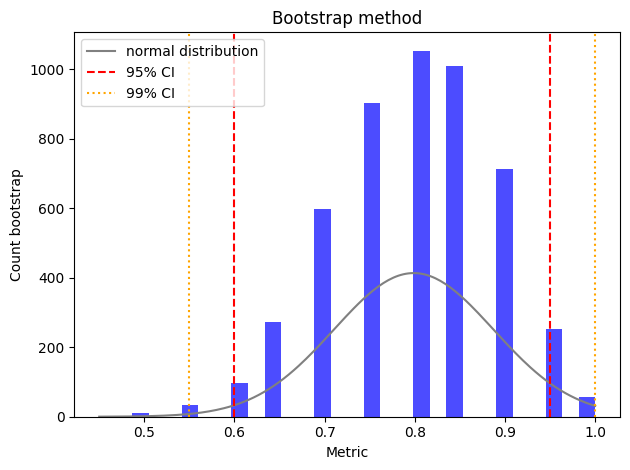

In [54]:
res_534_boot = valtest_stat_significance(sampler=sampler_ft,
                                         scorer=None,
                                         metric_agg='single_mean',
                                         data_type='test',
                                         main_column='final_metric',
                                         value_threshold=0.5,
                                         extra_samplers=None,
                                         bootstrap=True,
                                         bootstrap_iterations = 5000,
                                         is_info=False,
                                         random_state = 42,
                                         p_value=None)

In [55]:
display(res_534_boot['report']['result_dataframes'][0])

,Значение p-value на test,Результат теста
0,0.0002,green


### Тест 5.3.5 — Анализ динамики ключевой метрики качества в зависимости от простых характеристик запроса

Для оценки семантики в аргумент `embedding_client` подаётся **OpenAI-совместимый клиент** с методом `embeddings.create(model=..., input=[...])`; название эмбеддинг-модели передаётся отдельно через `embedding_model_name`. Пример поднятия клиента:

In [49]:
import os
import sys
import time
import socket
import threading
import subprocess
from openai import OpenAI

giga = GigaChatAPI(contour=contour, api_url=total_auth[contour]['API_URL'], auth_data=AUTH_DATA)
base_url = total_auth[contour]['API_URL']

def ensure_proxy_killed(port=8090):
    """Force-kill any process listening on the given port (mandatory)."""
    try:
        result = subprocess.run(
            f"netstat -ano | findstr :{port}",
            shell=True, capture_output=True, text=True
        )
        for line in result.stdout.splitlines():
            if "LISTENING" in line:
                pid = line.strip().split()[-1]
                subprocess.run(f"taskkill /F /PID {pid}", shell=True)
    except Exception:
        pass

ensure_proxy_killed(8090)

def start_proxy_subprocess(base_url, access_token, host='127.0.0.1', port=8090):
    env = os.environ.copy()
    env.update({
        'GPT2GIGA_MODE': 'DEV',
        'GPT2GIGA_HOST': host,
        'GPT2GIGA_PORT': str(port),
        'GPT2GIGA_LOG_FILENAME': 'proxy.log',
        'GPT2GIGA_ENABLE_API_KEY_AUTH': 'False',
        'GIGACHAT_ACCESS_TOKEN': access_token,
        'GIGACHAT_BASE_URL': base_url,
        'GIGACHAT_VERIFY_SSL_CERTS': 'False',
    })
    process = subprocess.Popen([sys.executable, '-m', 'gpt2giga.api_server'],
                               env=env,
                               stdout=subprocess.DEVNULL,
                               stderr=subprocess.DEVNULL)
    return process

def wait_port(host, port, timeout=40):
    """Ждёт, пока порт станет доступным."""
    deadline = time.time() + timeout
    while time.time() < deadline:
        try:
            with socket.create_connection((host, port), timeout=1):
                return True
        except OSError:
            time.sleep(0.5)
    return False

def configure_client_subprocess(base_url, access_token, host='127.0.0.1', port=8090, timeout=500):
    """
    Запускает прокси через subprocess, ждёт его готовности и возвращает OpenAI-клиент,
    а также объект процесса (чтобы потом завершить).
    """
    process = start_proxy_subprocess(base_url, access_token, host, port)
    if not wait_port(host, port):
        raise RuntimeError(f"Прокси не запустился на {host}:{port} за отведённое время")
    client = OpenAI(base_url=f'http://{host}:{port}/v1', api_key='123', timeout=timeout)
    return client, process

embedding_client, proxy_process = configure_client_subprocess(
    base_url=base_url,
    access_token=giga.token
)

Для демонстрации создается функция подсчета эмбеддингов, однако передавать ее при наличии полных трейсов (с заполненной колонкой `llm_prompt_tokens`) не рекомендуется!

In [50]:
import numpy as np
from tqdm import tqdm
from gigachat import GigaChat

# Для демонстрации создается функция подсчета эмбеддингов, однако передавать ее при наличии полных трейсов не рекомендуется!
def get_tokens(sentences):
    giga = GigaChat(credentials=AUTH_DATA,
            model='GigaChat',
            scope='GIGACHAT_API_CORP',
            base_url=total_auth[contour]['API_URL'],
            auth_url=total_auth[contour]['OAUTH_URL'],
            verify_ssl_certs=False)
    tokens = []
    for u in tqdm(sentences):
        out = giga.tokens_count([u], model='GigaChat') 
        tokens.append(out[0].tokens)
    return np.array(tokens)

100%|████████████████████████████████████████████████████████████████████████████████| 247/247 [00:04<00:00, 54.53it/s]


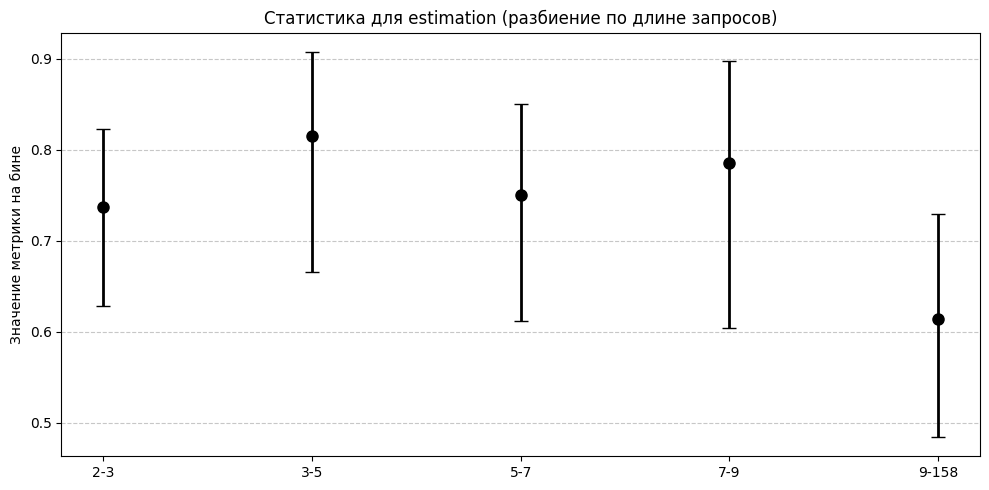

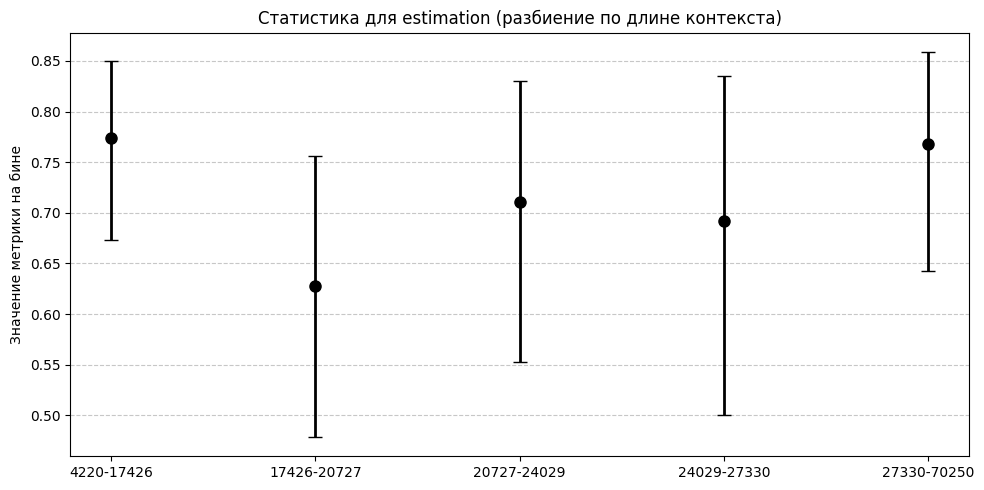

In [51]:
from llm_val.val_test.model_quality.valtest_metric_by_trivial_params import valtest_metric_by_trivial_params

res_535 = valtest_metric_by_trivial_params(sampler=sampler_traces2,
                                           scorer=scorer,
                                           token_counter_func=get_tokens,
                                           embedding_client=embedding_client,
                                           business_threshold=0.6,
                                           clustering_algo='hdbscan',
                                           stattest_method='bootstrap',
                                           context_test=True)

In [52]:
display(res_535['report']['result_dataframes'][0])
display(res_535['report']['result_dataframes'][1])
display(res_535['report']['result_dataframes'][2])

,bin_metric,other_metric,bin_size,other_size,p-value,diff_ratio,business_thr_p_val,business_thr_ratio,bounds
0,0.737,0.725,76,171,0.536,1.02,0.996,1.23,2-3
1,0.816,0.713,38,209,0.924,1.14,0.999,1.36,3-5
2,0.750,0.724,48,199,0.654,1.04,0.989,1.25,5-7
3,0.786,0.721,28,219,0.793,1.09,0.987,1.31,7-9
4,0.614,0.763,57,190,0.022,0.80,0.585,1.02,9-158


,cluster_metric,other_metric,cluster_size,other_size,p-value,diff_ratio,sample_questions
0,0.718,0.741,131,116,0.331,0.97,"[проанализируй мой портфель, Расскажи о состоя..."
1,0.897,0.706,29,218,0.993,1.27,"[Анализ финансов, Анализ финансов, Анализ фина..."
2,0.690,0.750,87,160,0.158,0.92,"[что за вклад 32 тыс, депозит на 5 месяцев под..."


,bin_metric,other_metric,bin_size,other_size,p-value,diff_ratio,business_thr_p_val,business_thr_ratio,bounds
0,0.774,0.706,84,163,0.874,1.10,1.000,1.29,4220-17426
1,0.628,0.750,43,204,0.066,0.84,0.645,1.05,17426-20727
2,0.711,0.732,38,209,0.404,0.97,0.927,1.18,20727-24029
3,0.692,0.733,26,221,0.354,0.94,0.837,1.15,24029-27330
4,0.768,0.717,56,191,0.789,1.07,0.998,1.28,27330-70250


In [53]:
proxy_process.kill()
proxy_process.wait(timeout = 5)

1

### Тест 5.3.6 - Анализ времени работы и степени зацикленности агента

In [26]:
from llm_val.val_test.traces.valtest_loop_duration_analysis import valtest_loop_duration_analysis

In [ ]:
res536 = valtest_loop_duration_analysis(sampler_traces)

In [28]:
display(res536['report']['result_dataframes'][0])

,Нода,Среднее время,Среднее время без выбросов,Зацикленность в начало,Зацикленность в себя,"Зацикленность ""Возврат""","Зацикленность ""Пинг-Понг""",Зацикленность в прозвольную ноду
0,ChatPromptTemplate,0.00,0.00,0.00,0.00,0.00,0.00,0.00
1,GigaChat,3.08,2.72,0.00,0.00,0.00,0.00,1.00
2,PromptTemplate,0.00,0.00,0.00,0.00,0.00,0.00,0.63
3,RunnableSequence,3.11,2.75,0.00,0.00,0.00,0.00,1.00
4,buttons_node,8.08,7.42,0.00,0.00,0.00,0.00,0.00
5,end_question_node,0.01,0.00,0.00,0.00,0.00,0.00,0.00
6,fewshots_node,0.18,0.15,0.00,0.00,0.00,0.00,0.00
7,generate_buttons_node,2.81,2.63,0.00,0.00,0.00,0.00,0.00
8,generate_node,3.13,2.61,0.00,0.00,0.00,0.00,0.00
9,nodes_classifier,0.00,0.00,0.00,0.00,0.00,0.00,0.00


### Тест 5.3.7 - Оценка информативности критериев

In [8]:
from llm_val.val_test.data_quality.valtest_criterion_informativeness import valtest_criterion_informativeness

res_537 = valtest_criterion_informativeness(sampler_ft,
                                            criterion_columns=['final_metric'],
                                            uninformativeness_threshold=0.05)

In [9]:
print(f'Значение метрики: {res_537["precomputed"]["measures"]}')

Значение метрики: {'final_metric': 0.19037317468902107}


In [10]:
display(res_537['report']['result_dataframes'][0])

,Критерий,Мера информативности на test,Неинформативный (мера < 0.05)
0,final_metric,0.1904,False


In [11]:
display(res_537['report']['result_dataframes'][1])

,Показатель,Значение
0,Доля неинформативных критериев,0.0%
1,Порог меры,0.05
2,Результат теста,green
3,Сводка,Доля «неинформативных» критериев – 0.0% (0/1 к...
4,Не найденные критерии,[]


### Тест 5.3.9 – Достижение требуемого качества по ключевой метрике в разрезе тематик/доменов

In [40]:
from copy import deepcopy

data_scenarios = deepcopy(data_ft)

scenarios = ['finance', 'investments', 'savings', 'analytics']
data_scenarios['scenario'] = pd.Series(scenarios).sample(n=len(data_traces), 
                                                         replace=True, 
                                                         ignore_index=True)

sampler_scenarios = FastTrackSampler(data_scenarios)

In [41]:
from llm_val.val_test.model_quality.valtest_metric_by_thema_agent import valtest_metric_by_thema_agent

res_539 = valtest_metric_by_thema_agent(sampler_scenarios,
                                        scorer=scorer,
                                        main_metric='single_mean_final_metric',
                                        business_metric_threshold=0.7,
                                        metric_agg='single_mean',
                                        data_type='test')

In [42]:
display(res_539['report']['result_dataframes'][0])
display(res_539['report']['result_dataframes'][1])

,,Ключевая метрика качества,Результат теста
Тематика,Наименование критерия,,
investments,single_mean_final_metric,0.909091,green
finance,single_mean_final_metric,0.833333,yellow
analytics,single_mean_final_metric,0.333333,yellow
Общий итог,,,yellow


,Количество элементов в разрезе сценариев
investments,11
finance,6
analytics,3


### Тест 5.3.10 - Динамика ключевой метрики в зависимости от длины истории диалога

In [43]:
import numpy as np
import pandas as pd
from llm_val.sampler.Sampler import Sampler

rng = np.random.default_rng(42)
n_dialogs = 120
session_ids = [f'sess_{i}' for i in range(n_dialogs)]

turn_counts = rng.integers(1, 8, size=n_dialogs)
dialogues = [[(f'q{j}', 'реплика пользователя', 'ответ решения') for j in range(int(k))]
             for k in turn_counts]
tokens_per_dialog = rng.integers(100, 2000, size=n_dialogs)
metric_value = rng.uniform(0.7, 1.0, size=n_dialogs)

X_dialog = pd.DataFrame({'session_id': session_ids, 'dialogue': dialogues})
y_dialog = pd.DataFrame({'metric_value': metric_value})
traces_dialog = pd.DataFrame({'session_id': session_ids,
                              'span_id': [f'span_{i}' for i in range(n_dialogs)],
                              'llm_total_tokens': tokens_per_dialog})

sampler_dialog = Sampler(test={'X': X_dialog, 'y': y_dialog, 'traces': traces_dialog})

,p-value,Средняя КМ на подвыборке (test),Средняя КМ на всем датасете (test),Результат теста
Проверка по длине в токенах,0.210903,0.836229,0.846236,green
Проверка по числу реплик,0.374385,0.842237,0.846236,green


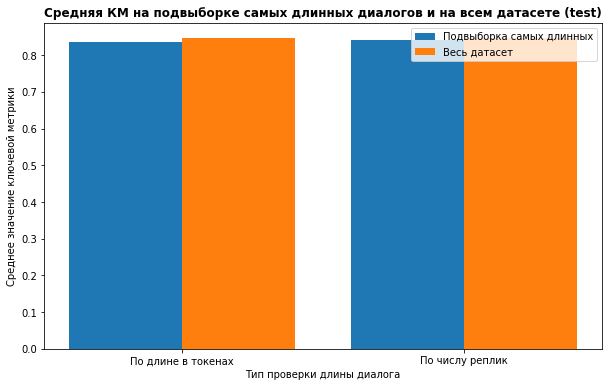

In [44]:
from llm_val.val_test.model_quality.valtest_metric_by_dialog_len import valtest_metric_by_dialog_len

res_5310 = valtest_metric_by_dialog_len(sampler_dialog,
                                        data_type='test',
                                        main_column='metric_value')

display(res_5310['report']['result_dataframes'][0])

### Тест 5.3.11 - Стабильность воспроизведения ответов на схожих запросах (Тест с необходимостью воспроизведения решения)

Для оценки семантики в аргумент `embedding_client` подаётся **OpenAI-совместимый клиент** с методом `embeddings.create(model=..., input=[...])`; название эмбеддинг-модели передаётся отдельно через `embedding_model_name`. Ниже показано, как поднять такой клиент функцией `configure_client` для GigaChat через прокси `gpt2giga`.

In [ ]:
import os
import sys
import time
import socket
import multiprocessing
import numpy as np
import pandas as pd
from openai import OpenAI
from llm_val.sampler.Sampler import Sampler
from llm_val.utils.api import GigaChatAPI


def _start_proxy(base_url, access_token, host, port):
    sys.argv = ['gpt2giga']
    os.environ['GPT2GIGA_MODE'] = 'DEV'
    os.environ['GPT2GIGA_HOST'] = host
    os.environ['GPT2GIGA_PORT'] = str(port)
    os.environ['GPT2GIGA_LOG_FILENAME'] = '/dev/null'
    os.environ['GPT2GIGA_ENABLE_API_KEY_AUTH'] = 'False'
    os.environ['GIGACHAT_ACCESS_TOKEN'] = access_token
    os.environ['GIGACHAT_BASE_URL'] = base_url
    os.environ['GIGACHAT_VERIFY_SSL_CERTS'] = 'False'
    import gpt2giga.api_server as api_server
    api_server.run()


def _wait_port(host, port, timeout=40):
    '''Ждёт, пока прокси начнёт принимать соединения на host:port'''
    deadline = time.time() + timeout
    while time.time() < deadline:
        try:
            with socket.create_connection((host, port), timeout=1):
                return True
        except OSError:
            time.sleep(0.5)
    return False


def configure_client(model, base_url, access_token, host='127.0.0.1', port=8090, timeout=500):
    '''Создаёт OpenAI-совместимый клиент: GigaChat через прокси gpt2giga'''
    process = multiprocessing.Process(target=_start_proxy,
                                      daemon=True,
                                      kwargs={'base_url': base_url, 'access_token': access_token,
                                              'host': host, 'port': port})
    process.start()
    _wait_port(host, port)
    return OpenAI(base_url=f'http://{host}:{port}/v1', api_key='123', timeout=timeout)


reprod_questions = ['Как оформить отпуск?', 'Какой остаток по счёту?', 'Сменить тариф']
reprod_answers = ['Отпуск оформляется через личный кабинет в разделе кадры.',
                  'Текущий остаток по вашему счёту составляет 12 500 рублей.',
                  'Тариф можно сменить в настройках профиля во вкладке услуги.']

X_reprod = pd.DataFrame({'input_query': reprod_questions,
                         'model_answer': reprod_answers})
y_reprod = pd.DataFrame({'metric_value': [1, 1, 1]})

sampler_reprod = Sampler(test={'X': X_reprod, 'y': y_reprod})

giga = GigaChatAPI(contour=contour, api_url=total_auth[contour]['API_URL'], auth_data=AUTH_DATA)
embedding_client = configure_client(model='EmbeddingsGigaR',
                                    base_url=total_auth[contour]['API_URL'],
                                    access_token=giga.token)

2026-07-02 11:29:00 | INFO     | - | Starting Gpt2Giga proxy server, version: 0.1.7


100%|██████████| 5/5 [00:32<00:00,  6.41s/it]


,Исходная,Аугментированная,Абсолютная разница,Относительная разница,Результат теста
Метрика,,,,,
Лексическое разнообразие,0.807282,0.967393,0.160111,0.198333,red
Семантическое разнообразие,0.049843,0.153479,0.103636,2.079262,green


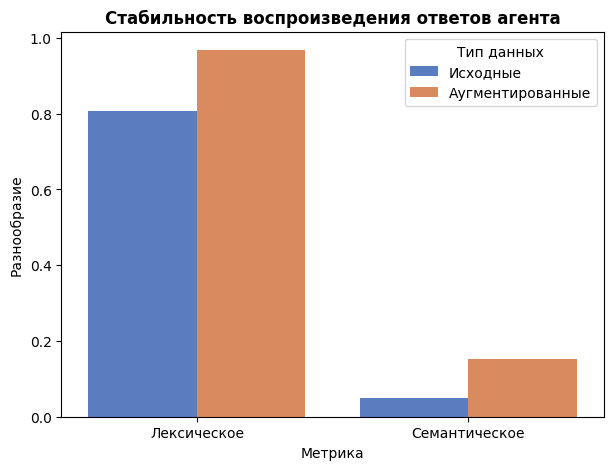

In [12]:
from llm_val.val_test.stability_without_target.valtest_answer_reprod_agent import valtest_answer_reprod_agent

res_5311 = valtest_answer_reprod_agent(sampler_reprod,
                                       data_type='test',
                                       model=model,
                                       is_long_answer=True,
                                       is_creative=True,
                                       n_generated_answers=5,
                                       embedding_client=embedding_client,
                                       embedding_model_name="EmbeddingsGigaR",
                                       augmentations_list=['use_special_symbol', 'use_translit_symbol'],
                                       p_augmented=0.2)

display(res_5311['report']['result_dataframes'][0])

### Тест 5.3.12 - Стабильность ответов в зависимости от аугментаций текстов на уровне слов (Тест с необходимостью воспроизведения решения)

Создадим OpenAI-совместимый клиент:

In [11]:
import os
import sys
import time
import socket
import multiprocessing
import numpy as np
import pandas as pd
from openai import OpenAI

from llm_val.utils.api import GigaChatAPI
from llm_val.sampler.Sampler import Sampler


def _start_proxy(base_url, access_token, host, port):
    sys.argv = ['gpt2giga']
    os.environ['GPT2GIGA_MODE'] = 'DEV'
    os.environ['GPT2GIGA_HOST'] = host
    os.environ['GPT2GIGA_PORT'] = str(port)
    os.environ['GPT2GIGA_LOG_FILENAME'] = '/dev/null'
    os.environ['GPT2GIGA_ENABLE_API_KEY_AUTH'] = 'False'
    os.environ['GIGACHAT_ACCESS_TOKEN'] = access_token
    os.environ['GIGACHAT_BASE_URL'] = base_url
    os.environ['GIGACHAT_VERIFY_SSL_CERTS'] = 'False'
    import gpt2giga.api_server as api_server
    api_server.run()


def _wait_port(host, port, timeout=40):
    '''Ждёт, пока прокси начнёт принимать соединения на host:port'''
    deadline = time.time() + timeout
    while time.time() < deadline:
        try:
            with socket.create_connection((host, port), timeout=1):
                return True
        except OSError:
            time.sleep(0.5)
    return False


def configure_client(model, base_url, access_token, host='127.0.0.1', port=8090, timeout=500):
    '''Создаёт OpenAI-совместимый клиент: GigaChat через прокси gpt2giga'''
    process = multiprocessing.Process(target=_start_proxy,
                                      daemon=True,
                                      kwargs={'base_url': base_url, 'access_token': access_token,
                                              'host': host, 'port': port})
    process.start()
    _wait_port(host, port)
    return OpenAI(base_url=f'http://{host}:{port}/v1', api_key='123', timeout=timeout)



giga = GigaChatAPI(contour=contour, api_url=total_auth[contour]['API_URL'], auth_data=AUTH_DATA)

In [20]:
aug_client = configure_client(model='GigaChat-2-Max',
                              base_url=total_auth[contour]['API_URL'],
                              access_token=giga.token)
aug_model_name = 'GigaChat-2-Max'

2026-07-22 15:30:29 | INFO     | - | Starting Gpt2Giga proxy server, version: 0.1.7
2026-07-22 15:30:29 | INFO     | - | Proxy settings: {'mode': 'DEV', 'host': '127.0.0.1', 'port': 8090, 'use_https': False, 'https_key_file': None, 'https_cert_file': None, 'pass_model': True, 'pass_token': False, 'embeddings': 'EmbeddingsGigaR', 'enable_images': True, 'enable_reasoning': False, 'structured_output_mode': 'function_call', 'log_level': 'INFO', 'log_filename': '/dev/null', 'log_max_size': 10485760}


Для примера в качестве модели решения также возьмем GigaChat:

In [13]:
class OpenAIModelWrapper:
    def __init__(self,
                 client: tp.Any,
                 model_name: str,
                 system_prompt: str = 'Отвечай кратко, одним словом или короткой фразой.',
                 temperature: float = 0.0,
                 max_tokens: int = 256,
                 timeout: float = 120.0,
                 retry_delay: float = 1.0,
                 max_attempts: int = 3):
        self.client = client
        self.model_name = model_name
        self.system_prompt = system_prompt
        self.temperature = temperature
        self.max_tokens = max_tokens
        self.timeout = timeout
        self.retry_delay = retry_delay
        self.max_attempts = max_attempts

    def _call_single(self, prompt: str) -> str:
        messages = [
            {"role": "system", "content": self.system_prompt},
            {"role": "user", "content": prompt},
        ]
        response = self.client.chat.completions.create(
            model=self.model_name,
            messages=messages,
            temperature=self.temperature,
            max_tokens=self.max_tokens,
        )
        return (response.choices[0].message.content or "").strip()

    def predict(self, prompts: tp.List[str]) -> tp.List[str]:
        results = []
        for prompt in prompts:
            answer = call_with_retries(
                self._call_single,
                timeout=self.timeout,
                retry_delay=self.retry_delay,
                max_attempts=self.max_attempts,
                func_args=(prompt,)
            )
            results.append(answer)
        return results


model = OpenAIModelWrapper(client=aug_client,
                           model_name=aug_model_name,
                           system_prompt='Отвечай кратко, одним словом или короткой фразой. Не добавляй пояснений.',
                           temperature=0.0,
                           max_tokens=128)

In [15]:
X_queries = pd.DataFrame({
    'input_query': [
        'Какая столица у Франции?',
        'Кто написал Войну и мир?',
        'Сколько будет 2+2?',
        'Какая самая высокая гора в мире?',
        'Столица Японии?',
    ],
    'output_answer': [
        'Париж',
        'Лев Толстой',
        'Четыре',
        'Эверест',
        'Токио',
    ],
    'reference_answer': [
        'Париж',
        'Лев Толстой',
        'Четыре',
        'Эверест',
        'Токио',
    ],
})

y_queries = pd.DataFrame({'value_metric': [1] * len(X_queries)})
sampler = Sampler(test={'X': X_queries, 'y': y_queries})

In [21]:
from llm_val.val_test.stability.valtest_metric_aug_stability_word import valtest_metric_aug_stability_word

res5312 = valtest_metric_aug_stability_word(sampler=sampler,
                                            scorer=scorer,
                                            model=model,
                                            main_metric='single_mean_value_metric',
                                            augmentations_list=['paraphrase', 'synonym', 'translation'],
                                            translation_language='английский',
                                            word_replace_ratio=0.2,
                                            max_attempts=2,
                                            timeout=120.0,
                                            retry_delay=1.0,
                                            exec_env='default',
                                            aug_client=aug_client,
                                            aug_model_name=aug_model_name)

/home/work/23660478@sigma.sbrf.ru/.conda/envs/project_env_copy/lib/python3.11/site-packages/scipy/stats/_wilcoxon.py:199: UserWarning: Exact p-value calculation does not work if there are zeros. Switching to normal approximation.
  temp = _wilcoxon_iv(x, y, zero_method, correction, alternative, method, axis)
/home/work/23660478@sigma.sbrf.ru/.conda/envs/project_env_copy/lib/python3.11/site-packages/scipy/stats/_wilcoxon.py:199: UserWarning: Sample size too small for normal approximation.
  temp = _wilcoxon_iv(x, y, zero_method, correction, alternative, method, axis)
/home/work/23660478@sigma.sbrf.ru/.conda/envs/project_env_copy/lib/python3.11/site-packages/scipy/stats/_wilcoxon.py:199: UserWarning: Exact p-value calculation does not work if there are zeros. Switching to normal approximation.
  temp = _wilcoxon_iv(x, y, zero_method, correction, alternative, method, axis)
/home/work/23660478@sigma.sbrf.ru/.conda/envs/project_env_copy/lib/python3.11/site-packages/scipy/stats/_wilcoxon.py:

In [17]:
display(res5312['report']['result_dataframes'][0])

,Тип преобразования,Значение single_mean_value_metric на аугментированных данных,Абсолютное изменение single_mean_value_metric,Доля успешно аугментированных объектов,p-value,Стат. значимость (падения),Результат теста
0,paraphrase,0.8,0.2,1.0,0.841345,Нет,green
1,synonym,0.4,0.6,1.0,0.958368,Нет,green
2,translation,0.5,0.5,0.8,0.921350,Нет,green


Второй способ запуска теста - уже с ответами на аугментированные вопросы, полученные функцией `get_augmented_data` внутри теста:

In [22]:
X_queries = pd.DataFrame({
    'input_query': ['Какая столица Франции?', 'Кто написал Войну и мир?'],
    'reference_answer': ['Париж', 'Лев Толстой'],
    'output_answer': ['Париж', 'Лев Толстой'],
})

X_queries['aug_valtest_metric_aug_stability_word_paraphrase'] = [
    'Какой главный город Франции?',
    'Кто является автором романа Война и мир?'
]

X_queries['pred_aug_valtest_metric_aug_stability_word_paraphrase'] = [
    'Париж',
    'Лев Толстой'
]

y_queries = pd.DataFrame({'value_metric': [1] * len(X_queries)})

res5312_ = valtest_metric_aug_stability_word(sampler=Sampler(test={'X': X_queries, 'y': y_queries}),
                                             scorer=scorer,
                                             main_metric='single_mean_value_metric',
                                             augmentations_list=['paraphrase'])

display(res5312_['report']['result_dataframes'][0])

,Тип преобразования,Значение single_mean_value_metric на аугментированных данных,Абсолютное изменение single_mean_value_metric,Доля успешно аугментированных объектов,p-value,Стат. значимость (падения),Результат теста
0,paraphrase,1.0,0.0,1.0,1.0,Нет,green


### Тест 5.3.13 - Стабильность ответов в зависимости от аугментаций текстов на уровне символов (Тест с необходимостью воспроизведения решения)

Автооценка ответа на аугментированный запрос вынесена в аргумент `answer_checker` с сигнатурой `checker(query, model_answer, reference_answer=None)`. По умолчанию используется exact-match по `reference_answer`.

In [113]:
import pandas as pd
from llm_val.sampler.Sampler import Sampler
from llm_val.val_test.stability.valtest_metric_aug_stability_symbol import valtest_metric_aug_stability_symbol

X_queries = pd.DataFrame({'session_id': [0, 1, 2],
                          'query_id': [0, 1, 2],
                          'input_query': ['Как называется столица Франции?',
                                          'Где находится Эйфелева башня?',
                                          'В каком городе живёт пользователь?'],
                          'output_answer': ['Париж', 'Париж', 'Москва'],
                          'reference_answer': ['Париж', 'Париж', 'Москва']})
sampler_queries = Sampler(test={'X': X_queries, 
                                'y': pd.DataFrame({'metric_value': [1, 1, 1]})})

In [121]:
res_5313 = valtest_metric_aug_stability_symbol(sampler=sampler_queries,
                                               scorer=scorer,
                                               model=model,
                                               main_metric='single_mean_metric_value',
                                               p_augmented=0.1)

display(res_5313['report']['result_dataframes'][0])

100%|██████████| 3/3 [00:02<00:00,  1.02it/s]


,Тип преобразования,Значение ключевой метрики,Абсолютное изменение ключевой метрики,Относительное изменение ключевой метрики,Результат теста
0,human_level_augmentations,0.666667,0.333333,33.333333,red
1,symbol_swap,0.333333,0.666667,66.666667,red
2,butter_finger,0.333333,0.666667,66.666667,red


### Тест 5.3.14 – Стабильность выдачи RAG в зависимости от аугментаций текстов на уровне символов или слов

Создадим OpenAI-совместимый клиент:

In [14]:
import os
import sys
import time
import socket
import multiprocessing
import numpy as np
import pandas as pd
from openai import OpenAI

from llm_val.utils.api import GigaChatAPI


def _start_proxy(base_url, access_token, host, port):
    sys.argv = ['gpt2giga']
    os.environ['GPT2GIGA_MODE'] = 'DEV'
    os.environ['GPT2GIGA_HOST'] = host
    os.environ['GPT2GIGA_PORT'] = str(port)
    os.environ['GPT2GIGA_LOG_FILENAME'] = '/dev/null'
    os.environ['GPT2GIGA_ENABLE_API_KEY_AUTH'] = 'False'
    os.environ['GIGACHAT_ACCESS_TOKEN'] = access_token
    os.environ['GIGACHAT_BASE_URL'] = base_url
    os.environ['GIGACHAT_VERIFY_SSL_CERTS'] = 'False'
    import gpt2giga.api_server as api_server
    api_server.run()


def _wait_port(host, port, timeout=40):
    '''Ждёт, пока прокси начнёт принимать соединения на host:port'''
    deadline = time.time() + timeout
    while time.time() < deadline:
        try:
            with socket.create_connection((host, port), timeout=1):
                return True
        except OSError:
            time.sleep(0.5)
    return False


def configure_client(model, base_url, access_token, host='127.0.0.1', port=8090, timeout=500):
    '''Создаёт OpenAI-совместимый клиент: GigaChat через прокси gpt2giga'''
    process = multiprocessing.Process(target=_start_proxy,
                                      daemon=True,
                                      kwargs={'base_url': base_url, 'access_token': access_token,
                                              'host': host, 'port': port})
    process.start()
    _wait_port(host, port)
    return OpenAI(base_url=f'http://{host}:{port}/v1', api_key='123', timeout=timeout)

giga = GigaChatAPI(contour=contour, api_url=total_auth[contour]['API_URL'], auth_data=AUTH_DATA)

In [ ]:
aug_client = configure_client(model='GigaChat-2-Max',
                              base_url=total_auth[contour]['API_URL'],
                              access_token=giga.token)
aug_model_name = 'GigaChat-2-Max'

Для тестов раздела о качестве RAG-систем была создана новая, наравне с `Sampler` и `Scorer`, сущность - `RAGExecutor`. В реализации этой сущности должна происходить обработка текстов, их нарезка и укладка в векторную базу данных, которая должна позволять осуществлять поиск близких пассажей. Также внутри `RAGExecutor` необходимо иметь возможность вызывать получение эмбеддингов. Инициализация `RAGExecutor`'а осуществляется для всех тестов раздела.

`RAGExecutor` должен включать в себя следующие обязательные функции и методы:

* `get_parameters()` - метод, который должен возвращать основные параметры работы `RAGExecutor`'а;
* `embed_text(text)` - метод, который должен возвращать эмбеддинг для текста с использованием инициализированного внутри `RAGExecutor`'а эмбеддера. На вход получает текст, который обрабатывает и токенизирует согласно `text_process_config` и `encode_config`, а затем выдает эмбеддинг обработанного текста;
* `get_passages_with_embeddings(baseline, chunk_size, chunk_overlap)` - метод, который должен по ключу, формирующемуся из трех параметров входа, возвращать набор пассажей с их эмбеддингами. Должна быть реализована возможность обращения к `baseline` нарезке из векторной базы данных (при `baseline=True`) и к новым нарезкам из векторной базы данных (`baseline=False`, `chunk_size=N`, `chunk_overlap=M`, где `N` и `M` - размер пассажа и величина перекрытия соответственно);
* `get_topK_passages(baseline, questions, topK, chunk_size, chunk_overlap)` - метод, который должен возвращать `topK` релевантных к каждому элементу `questions` пассажей. Должна быть реализована возможность обращения к `baseline` нарезке из векторной базы данных (при `baseline=True`) и к новым нарезкам из векторной базы данных (`baseline=False`, `chunk_size=N`, `chunk_overlap=M`, где `N` и `M` - размер пассажа и величина перекрытия соответственно).
* `get_llm_answers(baseline, questions, systems, topK, chunk_size, chunk_overlap)` - метод, который должен возвращать словарь с ответами LLM и их эмбеддингами к каждому элементу `questions` под ключами `llm_answer` и `llm_answer_embedding` соответственно. Должна быть реализована возможность обращения к `baseline` нарезке из векторной базы данных (при `baseline=True`) и к новым нарезкам из векторной базы данных (`baseline=False`, `chunk_size=N`, `chunk_overlap=M`, где `N` и `M` - размер пассажа и величина перекрытия соответственно).


В библиотеке есть пример реализации сущности RAGExecutor под таким же названием. Обратите внимание, что в нем (на данный момент) поддерживается использование только pdf и txt файлов.

Для использования имеющегося `RAGExecutor`'а и дальнейшего проведения тестов раздела о качестве RAG-систем необходимо наличие локального репозитория с эмбеддером `e5-large`. Ссылки для скачивания: 

Sigma: https://sberosc.sigma.sbrf.ru/repo/hosted//hosted/ModelsDS/1abdf830-56e5-4b4a-96cf-2d32010abf2f/intfloat_multilingual-e5-large.zip

Alpha: https://sberosc.ca.sbrf.ru/repo/hosted//hosted/ModelsDS/1abdf830-56e5-4b4a-96cf-2d32010abf2f/intfloat_multilingual-e5-large.zip

Для инициализации `RAGExecutor` необходимо указать следующие параметры и конфиги:

`embed_model_path` - путь до локальной модели-эмбеддера, в ячейке ниже записан в переменную `e5_path`

`encode_config` - параметры токенизации модели-эмбеддера, в ячейке ниже записан в переменную `e5_encode`

`text_process_config` - параметры предобработки текста перед векторизацией, в ячейке ниже записан в переменную `text_process_config`

`documents_paths` - путь или список путей до документов для построения векторной базы данных, записан в одноименную переменную

`vectorstore_path` - путь до директории, где будет располагаться векторная база данных, записан в одноименную переменную

In [9]:
from llm_val.ragexecutor.RAGExecutor import RAGExecutor
from langchain.chat_models import GigaChat

# модель для использования RAGExecutor
chat_model = GigaChat(auth_url='https://sm-auth-sd.prom-88-89-apps.ocp-geo.ocp.sigma.sbrf.ru/api/v2/oauth',
                      credentials=AUTH_DATA,
                      verify_ssl_certs=False,
                      scope='GIGACHAT_API_CORP')

e5_path = '../src/llm_val/model/Embedder/multilingual-e5-large'
e5_encode = {
    'max_length': 512,
    'padding': True,
    'truncation': True,
    'return_tensors': 'pt'
}
text_process_config = {
    'use_text_cleaner': True,
    'use_lemmatization': True,
    'language': 'russian',
    'stopwords_path': 'data/brainstorm/ru_stop_words.txt'
}
documents_paths = 'data/sample_text_rag.txt'
vectorstore_path = 'data/rag_vectorstore'

/home/work/23352704@sigma.sbrf.ru/.my_venv/lib/python3.9/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
/tmp/ipykernel_2423702/260985693.py:4: LangChainDeprecationWarning: The class `GigaChat` was deprecated in LangChain 0.3.5 and will be removed in 1.0. An updated version of the class exists in the :class:`~langchain-gigachat package and should be used instead. To use it run `pip install -U :class:`~langchain-gigachat` and import as `from :class:`~langchain_gigachat import GigaChat``.
  chat_model = GigaChat(auth_url='https://sm-auth-sd.prom-88-89-apps.ocp-geo.ocp.sigma.sbrf.ru/api/v2/oauth',


In [10]:
executor_rag = RAGExecutor(embed_model_path=e5_path,
                           encode_config=e5_encode,
                           text_process_config=text_process_config,
                           documents_paths=documents_paths,
                           vectorstore_path=vectorstore_path,
                           topK=3,
                           chunk_size=800,
                           chunk_overlap=200,
                           topK_list=[0,1,2,3,4,5],
                           chunk_size_list=[600,800,1000],
                           chunk_overlap_list=[50,100,150],
                           chat_model=chat_model)

Creating an Extended Vectorstore: 100%|████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 12/12 [00:00<00:00, 15812.64it/s]


In [11]:
from llm_val.val_test.stability_without_target.valtest_rag_top_stability_agent import valtest_rag_top_stability_agent

res_5314 = valtest_rag_top_stability_agent(sampler=sampler_rag,
                                           executor=executor_rag,
                                           augmentations_list=['human_level_augmentations',
                                                               'symbol_swap',
                                                               'butter_finger',
                                                               'translation',
                                                               'paraphrase',
                                                               'synonym'],
                                           exec_env='default',
                                           data_type='test',
                                           semaphore_threshold=(0.2, 0.7),
                                           p_augmented=0.05,
                                           translation_language='английский',
                                           word_replace_ratio=0.1,
                                           seed=42,
                                           max_attempts=3,
                                           aug_client=aug_client,
                                           aug_model_name=aug_model_name,
                                           is_info=False)

In [12]:
res_5314['report']['semaphore']

'yellow'

In [13]:
display(res_5314['report']['result_dataframes'][0])

,Размер топа,IOU на уровне символов,IOU на уровне слов
0,1,0.466667,0.733333
1,2,0.688889,0.866667
2,3,0.573333,0.766667


### Тест 5.3.15 – Оценка поиска релевантного пассажа в RAG

In [35]:
from llm_val.val_test.rag_quality.valtest_rag_quality_agent import valtest_rag_quality_agent

In [36]:
res_5315 = valtest_rag_quality_agent(sampler=sampler_rag,
                                     topk=3,
                                     metric_list=['nDCG@k', 
                                                  'MAP@k', 
                                                  'MP@k', 
                                                  'AUC@k', 
                                                  'ERR@k', 
                                                  'MRR@k', 
                                                  'HitRate@k', 
                                                  'Recall@k'])

In [37]:
display(res_5315['report']['result_dataframes'][0])

,Название метрики,Название тематики,Значение метрики,Результат теста
0,nDCG@k,Рэй Брэдберри- Наказание без преступления,0.726186,yellow
1,MAP@k,Рэй Брэдберри- Наказание без преступления,0.700000,yellow
2,MP@k,Рэй Брэдберри- Наказание без преступления,0.333333,red
3,AUC@k,Рэй Брэдберри- Наказание без преступления,0.900000,green
4,ERR@k,Рэй Брэдберри- Наказание без преступления,0.400000,red
5,MRR@k,Рэй Брэдберри- Наказание без преступления,0.700000,yellow
6,HitRate@k,Рэй Брэдберри- Наказание без преступления,0.800000,green
7,Recall@k,Рэй Брэдберри- Наказание без преступления,0.800000,green


In [38]:
res_5315['report']['semaphore']

'red'

In [39]:
data_rag_wo_thema = data_rag.drop(columns=['thema'])
sampler_rag_wo_thema = RAGSamplerAgent(data_rag_wo_thema)

In [40]:
res_5315_wo_thema = valtest_rag_quality_agent(sampler=sampler_rag_wo_thema,
                                              topk=3,
                                              metric_list=['nDCG@k', 
                                                           'MAP@k', 
                                                           'MP@k', 
                                                           'AUC@k', 
                                                           'ERR@k', 
                                                           'MRR@k', 
                                                           'HitRate@k', 
                                                           'Recall@k'])
display(res_5315_wo_thema['report']['result_dataframes'][0])

,Название метрики,Значение метрики,Результат теста
0,nDCG@k,0.726186,yellow
1,MAP@k,0.700000,yellow
2,MP@k,0.333333,red
3,AUC@k,0.900000,green
4,ERR@k,0.400000,red
5,MRR@k,0.700000,yellow
6,HitRate@k,0.800000,green
7,Recall@k,0.800000,green


### Тест 5.3.16 - Анализ полезности рефлексии в работе решения

#### Логика отбора строк трейсов для проведения теста  
Для проведения теста необходимо получить ответы агента до и после рефлексии. Для каждой ноды в рамках сессии:  
- Находятся все срабатывания ноды по span_name;
- Берутся спаны с первым входом в ноду рефлексии и последним выходом;
- Для каждого находятся дочерние LLM-спаны (parent_span_id == span_id родительского спана, aef_kind == 'llm');
- Из input_text первого дочернего спана извлекается последний assistant-ответ (до рефлексии), из output_text последнего — ответ после рефлексии;
- Ответы векторизуются, вычисляется среднее косинусное расстояние.

Для оценки семантики в аргумент `embedding_client` подаётся **OpenAI-совместимый клиент** с методом `embeddings.create(model=..., input=[...])`; название эмбеддинг-модели передаётся отдельно через `embedding_model_name`. Пример поднятия клиента:

In [ ]:
import os
import sys
import time
import socket
import multiprocessing
import numpy as np
import pandas as pd
from openai import OpenAI
from llm_val.sampler.Sampler import Sampler
from llm_val.utils.api import GigaChatAPI


def _start_proxy(base_url, access_token, host, port):
    sys.argv = ['gpt2giga']
    os.environ['GPT2GIGA_MODE'] = 'DEV'
    os.environ['GPT2GIGA_HOST'] = host
    os.environ['GPT2GIGA_PORT'] = str(port)
    os.environ['GPT2GIGA_LOG_FILENAME'] = '/dev/null'
    os.environ['GPT2GIGA_ENABLE_API_KEY_AUTH'] = 'False'
    os.environ['GIGACHAT_ACCESS_TOKEN'] = access_token
    os.environ['GIGACHAT_BASE_URL'] = base_url
    os.environ['GIGACHAT_VERIFY_SSL_CERTS'] = 'False'
    import gpt2giga.api_server as api_server
    api_server.run()


def _wait_port(host, port, timeout=40):
    '''Ждёт, пока прокси начнёт принимать соединения на host:port'''
    deadline = time.time() + timeout
    while time.time() < deadline:
        try:
            with socket.create_connection((host, port), timeout=1):
                return True
        except OSError:
            time.sleep(0.5)
    return False


def configure_client(model, base_url, access_token, host='127.0.0.1', port=8090, timeout=500):
    '''Создаёт OpenAI-совместимый клиент: GigaChat через прокси gpt2giga'''
    process = multiprocessing.Process(target=_start_proxy,
                                      daemon=True,
                                      kwargs={'base_url': base_url, 'access_token': access_token,
                                              'host': host, 'port': port})
    process.start()
    _wait_port(host, port)
    return OpenAI(base_url=f'http://{host}:{port}/v1', api_key='123', timeout=timeout)


reprod_questions = ['Как оформить отпуск?', 'Какой остаток по счёту?', 'Сменить тариф']
reprod_answers = ['Отпуск оформляется через личный кабинет в разделе кадры.',
                  'Текущий остаток по вашему счёту составляет 12 500 рублей.',
                  'Тариф можно сменить в настройках профиля во вкладке услуги.']

X_reprod = pd.DataFrame({'input_query': reprod_questions,
                         'model_answer': reprod_answers})
y_reprod = pd.DataFrame({'metric_value': [1, 1, 1]})

sampler_reprod = Sampler(test={'X': X_reprod, 'y': y_reprod})

giga = GigaChatAPI(contour=contour, api_url=total_auth[contour]['API_URL'], auth_data=AUTH_DATA)
embedding_client = configure_client(model='EmbeddingsGigaR',
                                    base_url=total_auth[contour]['API_URL'],
                                    access_token=giga.token)

In [26]:
from llm_val.val_test.reflection.valtest_reflection_usefulness import valtest_reflection_usefulness

res5316 = valtest_reflection_usefulness(sampler=sampler_traces_reflection,
                                        reflection_nodes=["reflection_node_A", "reflection_node_B"],
                                        embedding_client=embedding_client,
                                        embedding_model_name="EmbeddingsGigaR")

display(res5316["report"]['result_dataframes'][0])

,Название ноды рефлексии,Среднее косинусное расстояние
0,reflection_node_A,0.391110
1,reflection_node_B,0.395008


### Тест 5.3.17 - Динамика ключевой метрики в зависимости от используемых инструментов

N.B.: Если в данных нет колонки `'aef_kind'`, то метрика будет считаться по всем нодам без учета фильтра `'aef_kind' == 'tool'`.

In [7]:
from llm_val.val_test.traces.valtest_tool_metric_dynamics import valtest_tool_metric_dynamics

res5317 = valtest_tool_metric_dynamics(sampler=sampler_traces_tool,
                                       scorer=scorer,
                                       data_type='test',
                                       metric_agg='single_mean',
                                       greater_is_better=True)

display(res5317['report']['result_dataframes'][0])

,Нода/инструмент,Метрика,Абсолютное (относительное) изменение
0,call_rag,0.3793,-0.1237 (-24.6%)
1,get_document_upload_date,0.4638,-0.0392 (-7.8%)
2,get_document_storage_start_date,0.4938,-0.0092 (-1.8%)
3,map_doc_name_to_code,0.5556,0.0525 (+10.4%)


### Тест 5.3.18 – Оценка доли неверно заполненных аргументов при вызове инструментов

In [1]:
from llm_val.val_test.traces.valtest_incorrect_tool_calls import valtest_incorrect_tool_calls

На вход теста необходимо подать сигнатуры функций, представляющие собой заполненный вручную словарь вида `{имя инструмента: {параметр: тип}}`

Также можно подать описания функций в виде словаря `{имя инструмента: ('описание инструмента')}`. Это поможет LLM в проверке пункта 3 по методике определить, корректно ли заполнены аргументы.

In [3]:
import typing as tp

signatures = {
          'get_document_storage_start_date': {
              'document_group_number': tp.Optional[str],
              'form_code': str,
          },
          'get_document_upload_date': {
              'form_code': str,
               'document_group_number': str,
          },
          'map_doc_name_to_code': {
              'doc_name': str,
          },
          'call_rag': {
              'text': str,
          },
     }

tool_descriptions = {
    'call_rag': (
        'Ищет релевантную информацию в базе знаний по пользовательскому запросу.'
    ),
    'get_document_storage_start_date': (
        'Возвращает дату начала хранения документа по его идентификатору.'
    ),
    'get_document_upload_date': (
        'Возвращает дату загрузки документа по его идентификатору.'
    ),
    'map_doc_name_to_code': (
        'Преобразует название документа в его внутренний код.'
    ),
}

Запуск теста с проверкой только п.2 - сравнение фактических аргументов с формальными:

In [4]:
res5318 = valtest_incorrect_tool_calls(sampler=sampler_traces_tool,
                                       data_type='test',
                                       signatures=signatures,
                                       check_p3=False)

In [5]:
print('Светофор:', res5318['report']['semaphore'])
display(res5318['report']['result_dataframes'][0])

Светофор: yellow


,tool_name,total_calls,error_count,error_rate,p2_error_count,p3_checked_calls,p3_error_count,p3_status
0,get_document_upload_date,6,6,1.0,6,0,None,disabled
1,call_rag,1,0,0.0,0,0,None,disabled
2,get_document_storage_start_date,11,0,0.0,0,0,None,disabled
3,map_doc_name_to_code,2,0,0.0,0,0,None,disabled


In [6]:
pd.set_option("display.max_colwidth", 150)
display(res5318['report']['result_dataframes'][1])

,Результат теста,Светофор
0,Общая доля некорректных вызовов: 30.00%. Инструменты с долей ошибок выше 50%: ['get_document_upload_date'].,yellow


Запуск теста с проверкой п.2 и п.3 - сравнение фактических аргументов с требуемыми:

N.B.: Проверка п.3 работает по настроению гигачата, но в целом адекватно.

В качестве LLM-судьи в аргумент `judge_client` подаётся **OpenAI-совместимый клиент** с методом `chat.completions.create(model=..., messages=[],...)`; название LLM передаётся отдельно через `judge_model_name`.

In [7]:
from openai import OpenAI

client = OpenAI(base_url="http://localhost:8090/v1", api_key="my-local-secret-key")

In [8]:
res5318_ = valtest_incorrect_tool_calls(sampler=sampler_traces_tool,
                                        data_type='test',
                                        signatures=signatures,
                                        tool_descriptions=tool_descriptions,
                                        judge_client=client,
                                        judge_model_name='GigaChat-3-Max',
                                        temperature=0.0,
                                        max_tokens=8,
                                        timeout=90.0,
                                        retry_delay=1.0,
                                        max_attempts=3)

In [9]:
print('Светофор:', res5318_['report']['semaphore'])
display(res5318_['report']['result_dataframes'][0])

Светофор: red


,tool_name,total_calls,error_count,error_rate,p2_error_count,p3_checked_calls,p3_error_count,p3_status
0,call_rag,1,1,1.000000,0,1,1.0,completed
1,get_document_upload_date,6,6,1.000000,6,0,NaN,no_p2_valid_calls
2,get_document_storage_start_date,11,4,0.363636,0,11,4.0,completed
3,map_doc_name_to_code,2,0,0.000000,0,2,0.0,completed


In [10]:
pd.set_option("display.max_colwidth", 200)
display(res5318_['report']['result_dataframes'][1])

,Результат теста,Светофор
0,"Общая доля некорректных вызовов: 55.00%. Общая доля некорректных вызовов превышает критический порог 30%. Инструменты с долей ошибок выше 50%: ['call_rag', 'get_document_upload_date'].",red
